In [1]:
import pandas as pd
from plots import plot_gap_histogram
from stackup import calc_rss, calc_worst_case, simulate_gaps, calc_pct_out_of_spec

df = pd.read_csv("data/housing_stack.csv")
df

,name,nominal,plus_tol,minus_tol,direction
0,Housing,50.00,0.10,0.10,1
1,Part A,12.00,0.05,0.05,-1
2,Part B,15.50,0.05,0.05,-1
3,Spacer,8.25,0.00,0.10,-1
4,Part C,13.75,0.08,0.08,-1


In [ ]:
nominals = df["nominal"].to_numpy()
plus_tols = df["plus_tol"].to_numpy()
minus_tols = df["minus_tol"].to_numpy()
directions = df["direction"].to_numpy()

what_if = df.copy()
what_if.loc[4, ["plus_tol", "minus_tol"]] = 0.05

min_gap, max_gap = calc_rss(nominals, plus_tols, minus_tols, directions)

plus_tols_wi = what_if["plus_tol"].to_numpy()
minus_tols_wi = what_if["minus_tol"].to_numpy()

min_gap_wi, max_gap_wi = calc_rss(nominals, plus_tols_wi, minus_tols_wi, directions)

print(f"Housing stack RSS range: {min_gap:.3f} to {max_gap:.3f} mm")
print(f"What-if stack RSS range: {min_gap_wi:.3f} to {max_gap_wi:.3f} mm")


Housing stack RSS range: 0.395 to 0.705 mm
What-if stack RSS range: 0.409 to 0.691 mm


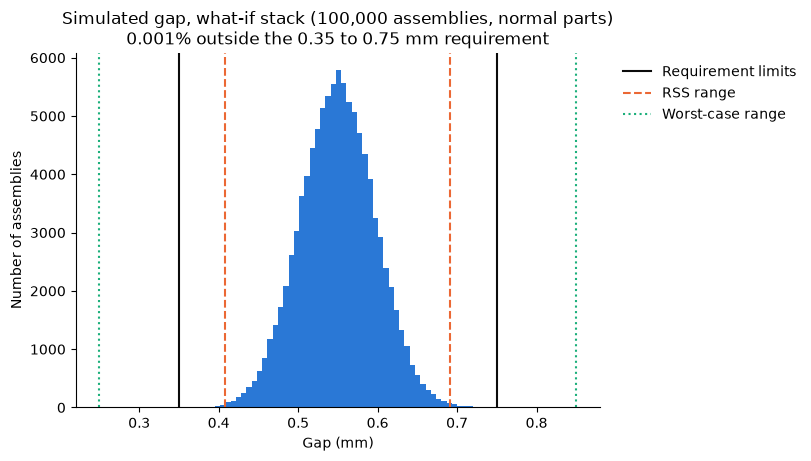

In [3]:
n_samples = 100_000
gaps = simulate_gaps(nominals, plus_tols_wi, minus_tols_wi, directions, n_samples=n_samples)

# Requirement
lower_limit = 0.35
upper_limit = 0.75

# Worst case limits
wc_limits = calc_worst_case(nominals, plus_tols_wi, minus_tols_wi, directions)

# RSS limits
rss_limits = calc_rss(nominals, plus_tols_wi, minus_tols_wi, directions)

# titles
title = f"Simulated gap, what-if stack ({n_samples:,} assemblies, normal parts)"

fig, ax = plot_gap_histogram(gaps, lower_limit, upper_limit, rss_limits, wc_limits, title)

fig.savefig("plots/what_if_gap_histogram_normal.png", dpi=150, bbox_inches="tight")



Tightening Part C to +/- 0.05 mm tolerance bought us 0.014 mm on both sides of the RSS range.